# 01 · Exploring the Spotify reviews dataset

Goal: confirm the data can support FeedbackPulse: enough reviews, real app versions, and a spread of ratings over time. Source and license: see `DATA_SOURCES.md`. Run `./scripts/download_data.sh` first.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

# userName is deliberately not loaded: we never need reviewer identities, and this
# notebook's output is committed to a public repo.
COLUMNS = [
    "reviewId",
    "content",
    "score",
    "thumbsUpCount",
    "reviewCreatedVersion",
    "at",
    "appVersion",
]
df = pd.read_csv(
    "../data/raw/spotify_reviews/spotify_reviews.csv",
    usecols=COLUMNS,
    parse_dates=["at"],
    dtype={"reviewCreatedVersion": "string", "appVersion": "string"},
)
print(f"{len(df):,} reviews · {df['at'].min().date()} → {df['at'].max().date()}")
# Review text stays out of the preview because it hasn't been PII-scrubbed yet (Step 3).
df.drop(columns="content").head(3)

84,165 reviews · 2018-09-12 → 2024-05-09


,reviewId,score,thumbsUpCount,reviewCreatedVersion,at,appVersion
0,437314fe-1b1d-4352-abea-12fec30fce58,4,0,<NA>,2024-05-09 16:28:13,<NA>
1,4933ad2c-c70a-4a84-957d-d405439b2e0f,5,0,8.9.38.494,2024-05-09 16:27:18,8.9.38.494
2,1ab275fb-59bf-42c7-88ef-b85901f0445e,5,0,8.9.36.616,2024-05-09 16:27:03,8.9.36.616


## Data quality
The things that would break the pipeline: missing versions, duplicates, empty text, non-English reviews.

In [2]:
pd.Series(
    {
        "reviewCreatedVersion missing %": round(df.reviewCreatedVersion.isna().mean() * 100, 1),
        "appVersion missing %": round(df.appVersion.isna().mean() * 100, 1),
        "rows where the two version columns differ": int(
            (
                df.reviewCreatedVersion.notna()
                & df.appVersion.notna()
                & (df.reviewCreatedVersion != df.appVersion)
            ).sum()
        ),
        "duplicate reviewId": int(df.reviewId.duplicated().sum()),
        "empty content": int(df.content.isna().sum()),
        "median text length (chars)": int(df.content.str.len().median()),
    }
).to_frame("value")

,value
reviewCreatedVersion missing %,6.9
appVersion missing %,6.9
rows where the two version columns differ,0.0
duplicate reviewId,0.0
empty content,0.0
median text length (chars),321.0


This dataset has no language column, so here's a rough proxy: the share of reviews where over 20% of characters are non-ASCII. Step 3 does proper language detection.

In [3]:
text = df.content.fillna("")
non_ascii = text.str.count(r"[^\x00-\x7F]") / text.str.len().clip(lower=1)
print(f"{(non_ascii > 0.2).mean():.1%} of reviews are mostly non-ASCII")

0.1% of reviews are mostly non-ASCII


## Ratings
App-store ratings are usually U-shaped: people mostly review when they love or hate something.

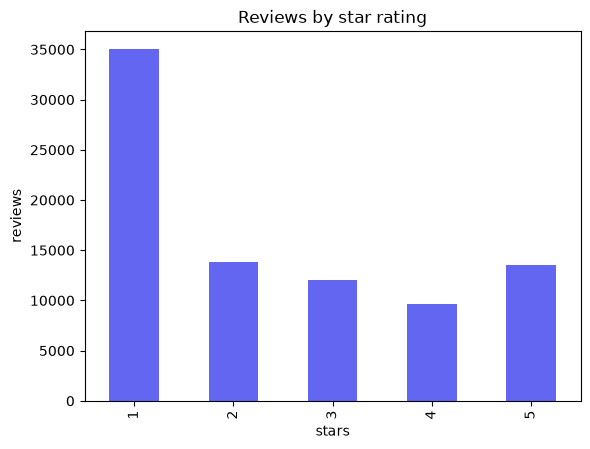

Average rating: 2.44 · 1–2 stars: 58.1%


In [4]:
ax = df.score.value_counts().sort_index().plot.bar(color="#6366f1", title="Reviews by star rating")
ax.set_xlabel("stars")
ax.set_ylabel("reviews")
plt.show()
print(f"Average rating: {df.score.mean():.2f} · 1–2 stars: {(df.score <= 2).mean():.1%}")

## Reviews and rating over time
Volume spikes and rating dips are what the Analyst will later explain. Volume also shows whether coverage is even across the date range.

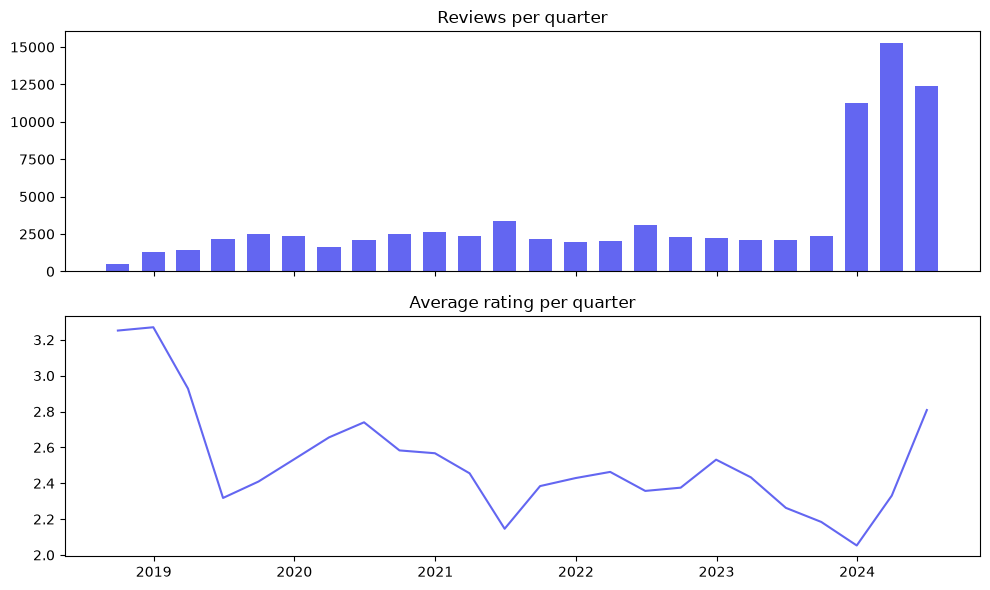

,reviews,avg_rating
at,,
2018-09-30,461,3.25
2018-12-31,1270,3.27
2019-03-31,1414,2.93
2019-06-30,2166,2.32
2019-09-30,2478,2.41
2019-12-31,2375,2.53
2020-03-31,1624,2.66
2020-06-30,2088,2.74
2020-09-30,2512,2.58


In [5]:
q = (
    df.set_index("at")
    .resample("QE")
    .agg(reviews=("reviewId", "size"), avg_rating=("score", "mean"))
)
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
axes[0].bar(q.index, q.reviews, width=60, color="#6366f1")
axes[0].set_title("Reviews per quarter")
axes[1].plot(q.index, q.avg_rating, color="#6366f1")
axes[1].set_title("Average rating per quarter")
plt.tight_layout()
plt.show()
q.round({"avg_rating": 2})

## Versions
Release comparisons are only trustworthy for versions with enough reviews, so we count how many clear each threshold.

In [6]:
versions = (
    df.dropna(subset=["reviewCreatedVersion"])
    .groupby("reviewCreatedVersion")
    .agg(reviews=("reviewId", "size"), avg_rating=("score", "mean"), first_seen=("at", "min"))
    .sort_values("first_seen")
)
pd.Series(
    {
        "versions": len(versions),
        "with 50+ reviews": int((versions.reviews >= 50).sum()),
        "with 200+ reviews": int((versions.reviews >= 200).sum()),
    }
).to_frame("count")

,count
versions,441
with 50+ reviews,252
with 200+ reviews,93


In [7]:
versions.sort_values("reviews", ascending=False).head(10).round({"avg_rating": 2})

,reviews,avg_rating,first_seen
reviewCreatedVersion,,,
8.8.96.364,4215,2.26,2023-12-15 09:08:21
8.9.36.616,3969,3.69,2024-05-02 18:12:54
8.9.34.590,2112,2.21,2024-04-24 09:10:53
8.8.92.700,2066,2.17,2023-11-30 00:14:23
8.9.24.633,1841,2.34,2024-03-20 10:08:31
8.8.88.397,1822,2.14,2023-11-16 09:23:54
8.9.18.512,1586,2.41,2024-02-27 21:00:30
8.9.20.574,1485,2.39,2024-03-08 08:59:58
8.9.30.433,1475,2.37,2024-04-10 10:01:19


## Biggest rating drops between releases
Comparing each well-reviewed version (200+ reviews) with the previous one by first-seen date. These are candidates for "what changed after this release?"; the causes are for the Analyst to find.

In [8]:
big = versions[versions.reviews >= 200].copy()
big["previous"] = big.index.to_series().shift()
big["previous_rating"] = big.avg_rating.shift()
big["change"] = big.avg_rating - big.previous_rating
big.sort_values("change").head(5)[
    ["previous", "previous_rating", "avg_rating", "change", "reviews", "first_seen"]
].round({"previous_rating": 2, "avg_rating": 2, "change": 2})

,previous,previous_rating,avg_rating,change,reviews,first_seen
reviewCreatedVersion,,,,,,
8.8.18.509,8.7.92.521,2.78,2.09,-0.69,295,2023-03-15 12:59:54
8.4.84.874,8.4.72.845,3.84,3.17,-0.66,304,2018-12-13 19:27:58
8.5.9.737,8.4.97.807,2.82,2.27,-0.55,225,2019-06-07 16:16:29
8.5.10.774,8.5.9.737,2.27,1.79,-0.48,396,2019-06-18 07:15:16
8.8.66.563,8.8.62.491,2.40,1.97,-0.43,315,2023-08-30 14:22:42


## Takeaways
- **Enough data:** 84,165 reviews, with 252 versions that have 50+ reviews.
- **Versions are usable:** present on 93.1% of rows, and the two version columns never disagree, so we keep `reviewCreatedVersion`. Reviews with no version stay in rating and theme trends but are left out of release comparisons.
- **Text is rich:** the median review is 321 characters, which gives clustering and theme labeling real content to work with.
- **Coverage is uneven:** Q4 2023 onward holds 46% of all reviews, against roughly 2,000 to 3,000 per quarter before that. This looks like a result of how the reviews were collected, so the jump in volume should not be read as real growth in reviews.
- **This is a sample:** the 2.44 average describes these reviews, not Spotify's store rating.
- **Cleaning needs (Step 3):** detect language, drop very short reviews, scrub PII, and never load `userName`.